In [423]:
import kagglehub
path = kagglehub.dataset_download("mosapabdelghany/medical-insurance-cost-dataset")

Using Colab cache for faster access to the 'medical-insurance-cost-dataset' dataset.


In [424]:
import os
os.listdir(path)

['insurance.csv']

In [482]:
import pandas as pd
df=pd.read_csv(path+'/insurance.csv')

In [483]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [484]:
df.shape

(1338, 7)

In [485]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [486]:
df.duplicated().sum()

np.int64(1)

In [487]:
df.drop_duplicates(inplace=True)

In [488]:
df.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


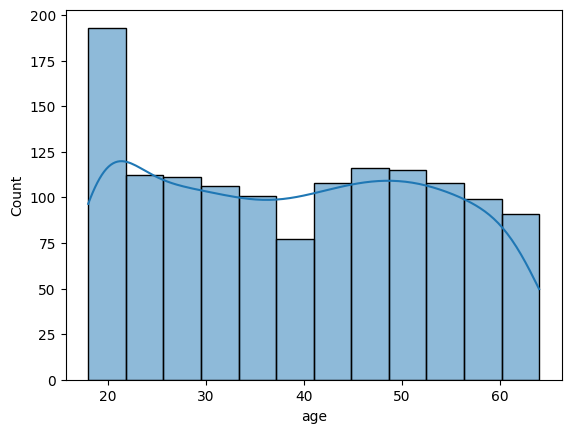

In [489]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(df,x='age',kde=True)
plt.show()

## We can visualize that most of the people are in the age group of 20 years

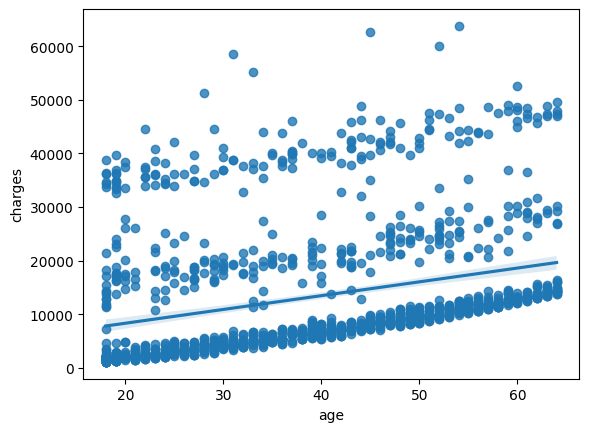

In [490]:
sns.regplot(df,x='age',y='charges')
plt.show()

In [491]:
df[df['charges']>50000]

,age,sex,bmi,children,smoker,region,charges
34,28,male,36.400,1,yes,southwest,51194.55914
543,54,female,47.410,0,yes,southeast,63770.42801
577,31,female,38.095,1,yes,northeast,58571.07448
819,33,female,35.530,0,yes,northwest,55135.40209
1146,60,male,32.800,0,yes,southwest,52590.82939
1230,52,male,34.485,3,yes,northwest,60021.39897
1300,45,male,30.360,0,yes,southeast,62592.87309


## We can see that as the age group is increasing, the mean charges for the insurance is almost constant while there are some individuals who are paying greater than 50k dollars.

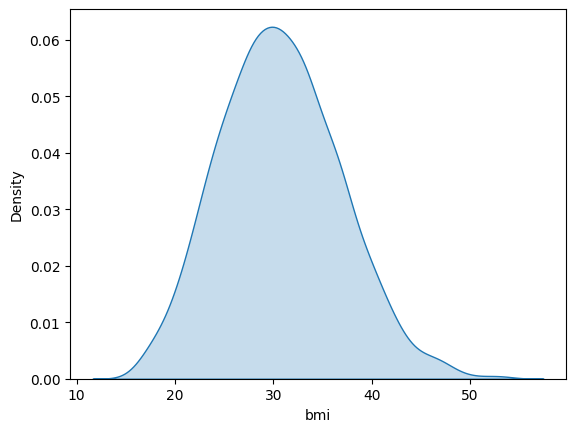

In [492]:
sns.kdeplot(df,x='bmi',fill=True)
plt.show()

## Normal Bmi range : (18.5,25)
## But according to dataset, most of the people comes in category greater than 25.

In [493]:
df['sex'].value_counts()

,count
sex,
male,675
female,662


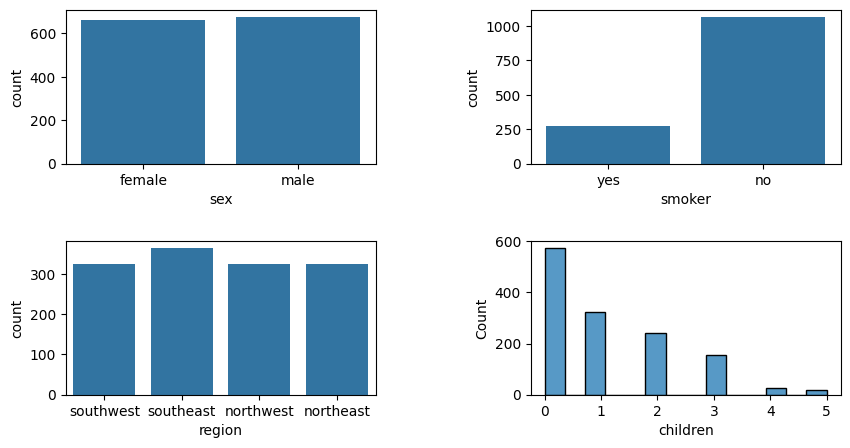

In [494]:
import seaborn as sns
import matplotlib.pyplot as plt
fig,ax=plt.subplots(2,2,figsize=(10,5))
sns.countplot(x='sex',data=df,ax=ax[0,0])
sns.countplot(x='smoker',data=df,ax=ax[0,1])
sns.countplot(x='region',data=df,ax=ax[1,0])
sns.histplot(x='children',data=df,ax=ax[1,1])
plt.subplots_adjust(hspace=0.5,wspace=0.5)
plt.show()

## We can visualize that males and females both opting for insurance are almost comparable.
## People from different regions are taking insurance equally with a little edge to southeast region people.
## People with more children are less interested in opting for insurance.
## Non smokers are scaling more to opt for the insurance and safety of themselves and family.

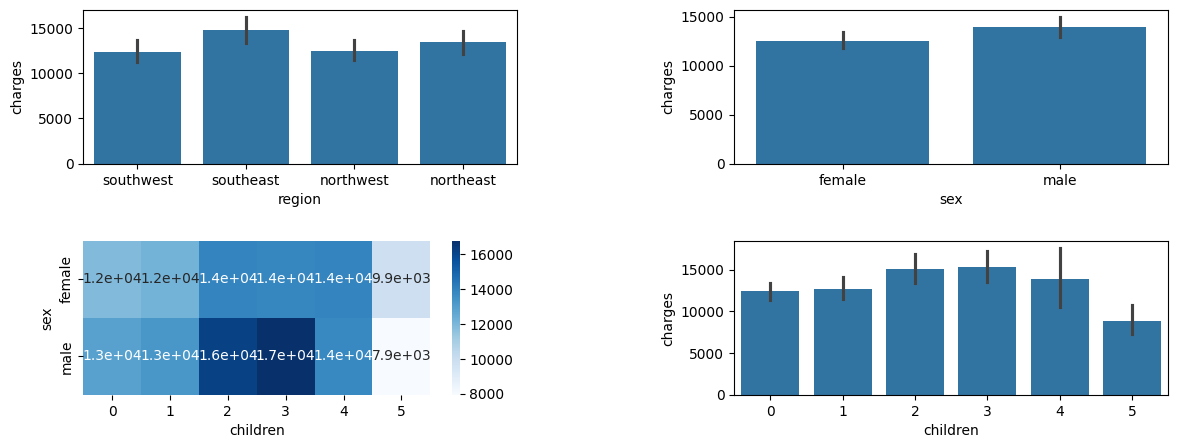

In [495]:
fig,ax=plt.subplots(2,2,figsize=(14,5))
sns.barplot(df,x='region',y='charges',ax=ax[0,0])
sns.barplot(df,x='sex',y='charges',ax=ax[0,1])
table1=pd.pivot_table(df,values='charges',columns='children',index='sex')
sns.heatmap(table1,annot=True,cmap='Blues',ax=ax[1,0])
sns.barplot(df,x='children',y='charges',ax=ax[1,1])
plt.subplots_adjust(hspace=0.5,wspace=0.5)
plt.show()

## Although the mean charges are high for the southeast region, then also people are more interestedly buying the insurance for their family.
## Males on average are investing more in the medical insurance.
## People with a family of 2 to 3 are interested more in purchasing the medical insurance plans.
## Males with a family size of 3-2 are spending most in the medical insurance.

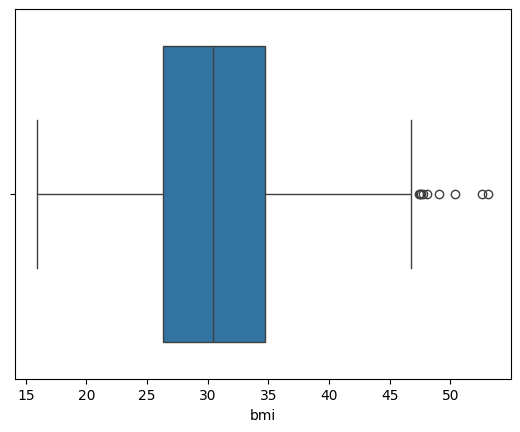

In [496]:
sns.boxplot(df,x='bmi')
plt.show()

In [497]:
def bmi_update(value):
  if value<=18.5:
    return 'Under Weight'
  elif value>=25:
    return 'Over Weight'
  else:
    return 'Normal'
df['age_bmi']=df['age']*df['bmi']
df['bmi']=df['bmi'].apply(bmi_update)

In [498]:
df.drop(columns=['age'],inplace=True)

In [499]:
df.sample()

,sex,bmi,children,smoker,region,charges,age_bmi
759,male,Over Weight,0,yes,southeast,36307.7983,687.06


In [500]:
df.to_csv('insurance.csv',index=False)

In [443]:
x=df.drop(columns=['charges'])
y=df['charges']

In [444]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [445]:
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((1069, 6), (268, 6), (1069,), (268,))

In [446]:
from sklearn.preprocessing import OneHotEncoder,LabelEncoder,StandardScaler

In [447]:
gen_le=LabelEncoder()
smoker_le=LabelEncoder()
x_train['sex']=gen_le.fit_transform(x_train['sex'])
x_test['sex']=gen_le.transform(x_test['sex'])
x_train['smoker']=smoker_le.fit_transform(x_train['smoker'])
x_test['smoker']=smoker_le.transform(x_test['smoker'])

In [448]:
import dill
with open('gender_label.pkl','wb') as f:
  dill.dump(gen_le,f)
with open('smoker_label.pkl','wb') as f:
  dill.dump(smoker_le,f)

In [449]:
df['region'].unique()

array(['southwest', 'southeast', 'northwest', 'northeast'], dtype=object)

In [450]:
ohe=OneHotEncoder(sparse_output=False,drop='first',handle_unknown='ignore')
features=ohe.fit_transform(x_train[['region','bmi']])
features=pd.DataFrame(features,columns=ohe.get_feature_names_out(),index=x_train.index).astype('int32')
x_train=pd.concat([x_train.drop(columns=['region','bmi']),features],axis=1)
features=ohe.transform(x_test[['region','bmi']])
features=pd.DataFrame(features,columns=ohe.get_feature_names_out(),index=x_test.index).astype('int32')
x_test=pd.concat([x_test.drop(columns=['region','bmi']),features],axis=1)

In [451]:
scaler=StandardScaler()
x_train[['age_bmi','children']]=scaler.fit_transform(x_train[['age_bmi','children']])
x_test[['age_bmi','children']]=scaler.transform(x_test[['age_bmi','children']])

In [501]:
with open('scaler.pkl','wb') as f:
  dill.dump(scaler,f)

In [452]:
x_train.head()

,sex,children,smoker,age_bmi,region_northwest,region_southeast,region_southwest,bmi_Over Weight,bmi_Under Weight
1114,1,-0.907908,0,-1.238320,0,0,0,0,0
968,1,0.766904,0,-1.282726,0,0,0,1,0
599,0,0.766904,0,1.430787,1,0,0,1,0
170,1,-0.907908,0,2.702873,0,1,0,1,0
275,0,0.766904,0,0.082162,0,0,0,1,0


In [453]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error,r2_score
model=RandomForestRegressor(max_depth=6)
model.fit(x_train,y_train)
train_pred=model.predict(x_train)
test_pred=model.predict(x_test)
print('Train MSE',mean_squared_error(y_train,train_pred))
print('Test MSE',mean_squared_error(y_test,test_pred))
print('Train R2',r2_score(y_train,train_pred))
print('Test R2',r2_score(y_test,test_pred))

Train MSE 21255152.374800853
Test MSE 30778735.406117145
Train R2 0.8447562094245589
Test R2 0.83250220575451


In [507]:
x_train.iloc[3,:]

,170
sex,1.000000
children,-0.907908
smoker,0.000000
age_bmi,2.702873
region_northwest,0.000000
region_southeast,1.000000
region_southwest,0.000000
bmi_Over Weight,1.000000
bmi_Under Weight,0.000000


In [509]:
model.predict([x_train.iloc[3,:]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


array([13352.81897492])

In [481]:
with open('ohe.pkl','wb') as f:
  dill.dump(ohe,f)
with open('model.pkl','wb') as f:
  dill.dump(model,f)